# Numerical Method for Solving Linear Systems of Equations

## System of Linear Equations

Given a matrix $n\times n$ matrix and a vector $b$, the goal is to solve the equation

$$
Ax = b.
$$

- Some algorithms to solve the system
- Apply the idea to image processing
- Understand the complexity of solving the system of linear equations.

## Main Theme:

- Computational Efficiency: How quickly can we solve a system of linear equations?
- Computational Cost: How many FLOPs (Floating-point operations: $+$, $-$, $\times$, $\div$) does the algorithm require so solve a system of equations?
- Accuracy: How close is the computed solution to the exact solution?
- Numerical stability: Does the algorithm amplify or reduce the error by rounding or finite precision arithmetic of floating point operations?

**Example:** Let $x$ be an image, and we can apply a transformation, $A$ to blur the image. Then to recover the original image, we have to solve $Ax = b$ for the original $x$.

Basically we can use Toeplitz matrix to blur the image

$$
A = \begin{pmatrix}
a_1 & a_2 & \cdots & 0 \\
a_2 & a_1 & a_2 & 0 \\
\vdots & \ddots & \ddots & \vdots \\
0 & 0 & \cdots & a_1
\end{pmatrix}
$$

a) Write a function to construct a $10 \times 10$ Toeplitz matrix with entries are 1.0, 0.9, 0.8 on the diagonal.

In [26]:
import numpy as np

from Lectures.Lecture02 import solns

from Lectures.Lecture03 import end_time

In [27]:
# construct A manually
# zero matrix
A = np.zeros((10, 10))

In [28]:
print(A)

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [29]:
# set 1.0 on the 1st diagonal
for i in range(10):
    A[i, i] = 1.0

In [30]:
print(A)

[[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]]


In [31]:
# set 0.9 on 2nd diagonals
for i in range(9):
    A[i, i + 1] = 0.9
    A[i + 1, i] = 0.9

In [32]:
print(A)

[[1.  0.9 0.  0.  0.  0.  0.  0.  0.  0. ]
 [0.9 1.  0.9 0.  0.  0.  0.  0.  0.  0. ]
 [0.  0.9 1.  0.9 0.  0.  0.  0.  0.  0. ]
 [0.  0.  0.9 1.  0.9 0.  0.  0.  0.  0. ]
 [0.  0.  0.  0.9 1.  0.9 0.  0.  0.  0. ]
 [0.  0.  0.  0.  0.9 1.  0.9 0.  0.  0. ]
 [0.  0.  0.  0.  0.  0.9 1.  0.9 0.  0. ]
 [0.  0.  0.  0.  0.  0.  0.9 1.  0.9 0. ]
 [0.  0.  0.  0.  0.  0.  0.  0.9 1.  0.9]
 [0.  0.  0.  0.  0.  0.  0.  0.  0.9 1. ]]


In [33]:
# set 0.8 on the 3rd diagonals
for i in range(8):
    A[i, i + 2] = 0.8
    A[i + 2, i] = 0.8

In [34]:
print(A)

[[1.  0.9 0.8 0.  0.  0.  0.  0.  0.  0. ]
 [0.9 1.  0.9 0.8 0.  0.  0.  0.  0.  0. ]
 [0.8 0.9 1.  0.9 0.8 0.  0.  0.  0.  0. ]
 [0.  0.8 0.9 1.  0.9 0.8 0.  0.  0.  0. ]
 [0.  0.  0.8 0.9 1.  0.9 0.8 0.  0.  0. ]
 [0.  0.  0.  0.8 0.9 1.  0.9 0.8 0.  0. ]
 [0.  0.  0.  0.  0.8 0.9 1.  0.9 0.8 0. ]
 [0.  0.  0.  0.  0.  0.8 0.9 1.  0.9 0.8]
 [0.  0.  0.  0.  0.  0.  0.8 0.9 1.  0.9]
 [0.  0.  0.  0.  0.  0.  0.  0.8 0.9 1. ]]


In [35]:
# Write a function to return a Toeplitz matrix
def gen_toeplitz_mat(n, v):
    # n: the size of the matrix
    # v: vector which contains the values on the diagonal
    A = np.zeros((n,n))
    k = len(v)
    # if v has more than n elements, we raise the error
    if k > n:
        raise ValueError('Too many values for v')
    for j in range(k):
        for i in range(n - j):
            A[i, i + j] = v[j]
            A[i + j, i] = v[j]

    return A

In [39]:
n = 10
v = [1.0, 0.9, 0.8]
A = gen_toeplitz_mat(n, v)
print(A)

[[1.  0.9 0.8 0.  0.  0.  0.  0.  0.  0. ]
 [0.9 1.  0.9 0.8 0.  0.  0.  0.  0.  0. ]
 [0.8 0.9 1.  0.9 0.8 0.  0.  0.  0.  0. ]
 [0.  0.8 0.9 1.  0.9 0.8 0.  0.  0.  0. ]
 [0.  0.  0.8 0.9 1.  0.9 0.8 0.  0.  0. ]
 [0.  0.  0.  0.8 0.9 1.  0.9 0.8 0.  0. ]
 [0.  0.  0.  0.  0.8 0.9 1.  0.9 0.8 0. ]
 [0.  0.  0.  0.  0.  0.8 0.9 1.  0.9 0.8]
 [0.  0.  0.  0.  0.  0.  0.8 0.9 1.  0.9]
 [0.  0.  0.  0.  0.  0.  0.  0.8 0.9 1. ]]


In [40]:
gen_toeplitz_mat(4, v=[1.0, 0.9, 0.8, 0.7, 0.6])

ValueError: Too many values for v

**Example:** Create an image with text: "ALABAMA"

In [41]:
%pip install pillow

Note: you may need to restart the kernel to use updated packages.


In [47]:
from PIL import Image, ImageDraw, ImageFont

In [48]:
# create an empty image
w = 300
h = 50

In [49]:
img = Image.new('L', (w, h), color=255)

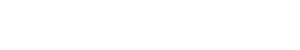

In [50]:
img

In [51]:
pen = ImageDraw.Draw(img)
font = ImageFont.load_default(size=36)
pen.text((0,0), "ALABAMA", fill=0, font=font)

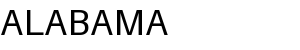

In [52]:
img

In data science (scientific computing), an image is just a matrix of numbers!

In [53]:
img_arr = np.array(img)

In [54]:
print(img_arr)

[[255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 ...
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]]


In [56]:
# We will blur this image using a Toeplitz matrix
# - flatten the image
# - create a matrix
# - multiply matrix
# convert the image into a vector
x = img_arr.flatten()

In [57]:
x

array([255, 255, 255, ..., 255, 255, 255], shape=(15000,), dtype=uint8)

In [58]:
n = x.shape[0]

In [59]:
A = gen_toeplitz_mat(n, v=[1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3])

In [60]:
print(A.shape)

(15000, 15000)


In [63]:
print(A[:10,:10])

[[1.  0.9 0.8 0.7 0.6 0.5 0.4 0.3 0.  0. ]
 [0.9 1.  0.9 0.8 0.7 0.6 0.5 0.4 0.3 0. ]
 [0.8 0.9 1.  0.9 0.8 0.7 0.6 0.5 0.4 0.3]
 [0.7 0.8 0.9 1.  0.9 0.8 0.7 0.6 0.5 0.4]
 [0.6 0.7 0.8 0.9 1.  0.9 0.8 0.7 0.6 0.5]
 [0.5 0.6 0.7 0.8 0.9 1.  0.9 0.8 0.7 0.6]
 [0.4 0.5 0.6 0.7 0.8 0.9 1.  0.9 0.8 0.7]
 [0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.  0.9 0.8]
 [0.  0.3 0.4 0.5 0.6 0.7 0.8 0.9 1.  0.9]
 [0.  0.  0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]]


In [64]:
x_blur = A@x

In [66]:
print(x_blur.shape)

(15000,)


In [67]:
x_blur[:10]

array([1326. , 1555.5, 1759.5, 1938. , 2091. , 2218.5, 2320.5, 2397. ,
       2397. , 2397. ])

In [68]:
# reshape to the original size 300x50
blur_image = x_blur.reshape(50, 300)

In [70]:
import matplotlib.pyplot as plt

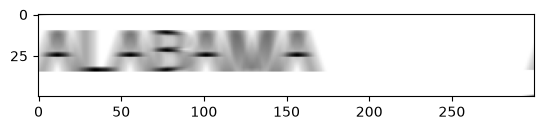

In [71]:
# blur_img is a matrix, not an image!
fig, ax = plt.subplots()
ax.imshow(blur_image, cmap='gray')
# set cmap=gray to turn the image to gray scale

## How to solve a system of linear equations numerically?

**Theorem:** If $A$ is invertable, $\det(A)\ne 0$, then the system $Ax=b$ has exact solution
$$
x = A^{-1}b.
$$

Getting the exact solutions is not efficient in scientific computing, so we have to approximate the solution with better accuracy.

*Case 1:* Simple cases: Triangular system.

## Forward Substitution for lower triangular system

Let $L$ be a lower triangular matrix.

$$
L = \begin{bmatrix}
l_{11} & 0 & \cdots & 0 \\
l_{21} & l_{22} & 0 & \cdots \\
\vdots & \vdots & \ddots & \vdots \\
1_{n1} & \cdots & \cdots & l_{m}
\end{bmatrix}
$$

($L$ has at most $\frac{n(n+1)}{2}$ non-zero entries)
and a vector
$$
b = [b_1, \ldots, b_n]
$$

Now we want to solve
$$
\begin{aligned}
&l_{11}x_1 = b_1 \\
&l_{21}x_1+l_{22}x_2 = b_2 \\
&\cdots \\
&l_{n1}x_1+l_{n2}x_2+\cdots+l_{nn}x_n=b_n \\
\end{aligned}
$$

Suppose $l_{ii}\ne 0$ for all $i$.

We can solve for $x_i$ as follows
$$
x_i = \frac{b_i - \sum_{j=1}^{i-1}l_{ij}*x_j}{l_{ii}}
$$

We can analyze the nnumbr of FLOPs (FLoating point operations: $+, -, \div, \times$)

To solve for $x_1$ we need $1$ FLOP, for $x_2$ we need $3$ FLOPs, $\cdots$, for $x_n$ we need $2(n-1)+1 = 2n-1$ FLOPs.

Total we have $1 + 3 + \cdots + 2n-1 = n^2$ FLOPs

So the cost of solving a system fo linear equations in the lower triangular case is $n^2$. There are two things we need to do:

- How can we solve this system? (Implement an algorithm to solve it)
- Do analysis to confirm the cost of the algorithm.

In [5]:
# get the idea to obtain general formula
for n in range(1, 21):
    s = 0
    for i in range(1, n + 1):
        s += 2*i - 1
    print(f"n = {n}, s = {s}")

n = 1, s = 1
n = 2, s = 4
n = 3, s = 9
n = 4, s = 16
n = 5, s = 25
n = 6, s = 36
n = 7, s = 49
n = 8, s = 64
n = 9, s = 81
n = 10, s = 100
n = 11, s = 121
n = 12, s = 144
n = 13, s = 169
n = 14, s = 196
n = 15, s = 225
n = 16, s = 256
n = 17, s = 289
n = 18, s = 324
n = 19, s = 361
n = 20, s = 400


**Implement the algorithm**

In [6]:
import numpy as np

In [25]:
def forward_sub(L, b):
    """
    Solve Lx = b
    return x as float
    """
    # init an empty vector
    x = np.empty_like(b).astype(float)
    n = len(b)
    if L.shape != (n,n):
        raise ValueError('The matrix L does not have the same size as b!')
    for i in range(n):
        if i == 0:
            x[i] = b[i] / L[i, i]
        else:
            x[i] = (b[i] - np.dot(x[:i], L[i, :i])) / L[i, i]
    return x

In [26]:
# test is
L = np.array([
    [1, 0],
    [1, 2]
])
b = np.array([1, 2])
forward_sub(L, b)

array([1. , 0.5])

In [27]:
# test to make sure it is right!
# generate random matrix
n = 20
L = np.tril(np.random.normal(loc=1.5, scale=0.8, size=(n, n)))
b = np.random.normal(loc=1.5, scale=1.2, size=n)
print(L.shape)
print(b.shape)
# solve the system Lx = b
x = forward_sub(L, b)
# use numpy to solve it
x_np = np.linalg.solve(L, b)
# make sure x and x_np are `equal`.
np.allclose(x_np, x)

(20, 20)
(20,)


True

**Cost Analysis:** Use the algorithm to solve random systems, record the running time and plot against the size $n$. We wish to obtain $O(n^2)$.

In [37]:
n_vals = np.arange(1000, 10_001, 100)

In [38]:
exc_time = []

In [39]:
import time

In [40]:
for n in n_vals:
    # generate matrix
    L = np.tril(np.random.normal(loc=1.5, scale=0.8, size=(n, n)))
    b = np.random.normal(loc=0, scale=1.2, size=n)
    # solve it
    start_time = time.time()
    # x = forward_sub(L, b)
    x = np.linalg.solve(L, b)
    end_time = time.time()
    exc_time.append(end_time - start_time)

KeyboardInterrupt: 